# <center>Computação Numérica — Projeto da Unidade II</center>
## <center>Identificação de um Sistema Dinâmico com RBF e MMQ</center>

**O que este notebook faz, em uma frase:** recebe os sinais medidos (com ruído) de um sistema físico em operação e obtém modelos matemáticos da sua dinâmica, avaliando cada modelo pelo **Erro Médio Quadrático (EMQ)** e pela **Correlação de Pearson ($r$)**.

### Os dados (`dados_projeto_02.csv`)
| Coluna | Significado |
|---|---|
| `t` | tempo (s), de 0 a 30 s, amostrado a cada $\Delta t = 0{,}02$ s (1501 amostras) |
| `u` | sinal de **entrada** do sistema: onda quadrada que alterna entre $+1$ e $-1$ |
| `x_ruido` | **saída 01** do sistema, medida com ruído |
| `y_ruido` | **saída 02** do sistema, medida com ruído |

### O modelo pedido no enunciado
$$y[n] = f\big(y[n-2],\; y[n-1],\; u[n],\; u[n-1]\big)$$
O valor da saída **agora** ($n$) depende dos **dois valores anteriores** da própria saída e dos valores **atual e anterior** da entrada. (O mesmo vale para a saída $x$.) O projeto pede para obter $f$ de duas formas:
* **com Funções de Base Radial (RBF)** — $f$ é uma soma de gaussianas (não linear);
* **com o Método dos Mínimos Quadrados (MMQ)** — $f$ é uma combinação linear dos 4 valores.

### Roteiro (cada item da avaliação → seção do notebook)
| Item do enunciado | Pontos | Onde está |
|---|---|---|
| Ajuste via Funções de Base Radial (RBF) | 2,0 | Seção 4 (Etapa 01) |
| Erro Médio Quadrático (EMQ) | 1,0 | Seção 4 (Etapa 02) |
| Regressão linear entre dados reais e ajustados | 1,0 | Seção 4 (Etapa 03) |
| Coeficiente de Correlação de Pearson | 2,0 | Seção 4 (Etapa 03) |
| Repetir o processo com o Método dos Mínimos Quadrados (MMQ) | 2,0 | Seção 5 (Etapa 04) |
| Conclusões | 2,0 | Seção 8 |

A **Seção 3** é um passo de preparação: mostra a RBF no caso mais simples (uma entrada só, o tempo), o que ajuda a entender a ideia e ainda fornece uma versão "limpa" (filtrada) dos sinais para usar como referência nos gráficos.

Bibliotecas usadas: apenas **NumPy** (vetores e álgebra linear) e **Matplotlib** (gráficos). Todas as fórmulas (RBF, equação normal, EMQ, Pearson, regressão) foram implementadas "na mão".

In [1]:
import csv                        # leitor de CSV da biblioteca padrão do Python (só para separar as colunas)
import numpy as np                # vetores, matrizes e álgebra linear
import matplotlib.pyplot as plt   # gráficos

# Aparência dos gráficos: grade discreta e sem bordas superior/direita
plt.rcParams.update({"axes.grid": True, "grid.linestyle": ":", "grid.alpha": 0.5,
                     "axes.spines.top": False, "axes.spines.right": False})

# Cores usadas em todo o notebook (sempre o mesmo papel para a mesma cor)
COR_MEDIDO = "#2a78d6"   # azul    -> dados medidos (com ruído)
COR_RBF = "#eb6834"      # laranja -> modelo RBF
COR_MMQ = "#6250d6"      # violeta -> modelo MMQ
COR_ENTRADA = "#52514e"  # cinza   -> sinal de entrada u(t)

---
## 1. Leitura dos dados

O arquivo usa **vírgula como separador decimal** (padrão brasileiro: `"0,02"`), e os números com vírgula vêm entre aspas para não serem confundidos com o separador de colunas. Por isso:
1. o módulo `csv` separa as 4 colunas respeitando as aspas;
2. trocamos `,` por `.` em cada valor e convertemos para `float`.

In [2]:
linhas = []
with open("dados_projeto_02.csv", "r", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo)
    cabecalho = next(leitor)                      # primeira linha: nomes das colunas
    for linha in leitor:
        if linha:                                 # ignora linhas vazias
            linhas.append([float(valor.replace(",", ".")) for valor in linha])

dados = np.array(linhas)                          # matriz (1501 linhas x 4 colunas)
t = dados[:, 0]   # tempo (s)
u = dados[:, 1]   # entrada
x = dados[:, 2]   # saída 01 medida (com ruído)
y = dados[:, 3]   # saída 02 medida (com ruído)
N = len(t)

print("Colunas:", cabecalho)
print(f"Número de amostras N = {N}  |  t de {t[0]} a {t[-1]} s  |  Δt = {t[1] - t[0]:.2f} s")
print("Primeiras 3 linhas:\n", dados[:3])

Colunas: ['t', 'u', 'x_ruido', 'y_ruido']
Número de amostras N = 1501  |  t de 0.0 a 30.0 s  |  Δt = 0.02 s
Primeiras 3 linhas:
 [[ 0.        0.        0.030472 -0.043722]
 [ 0.02      1.       -0.103998  0.09276 ]
 [ 0.04      1.        0.075178  0.036407]]


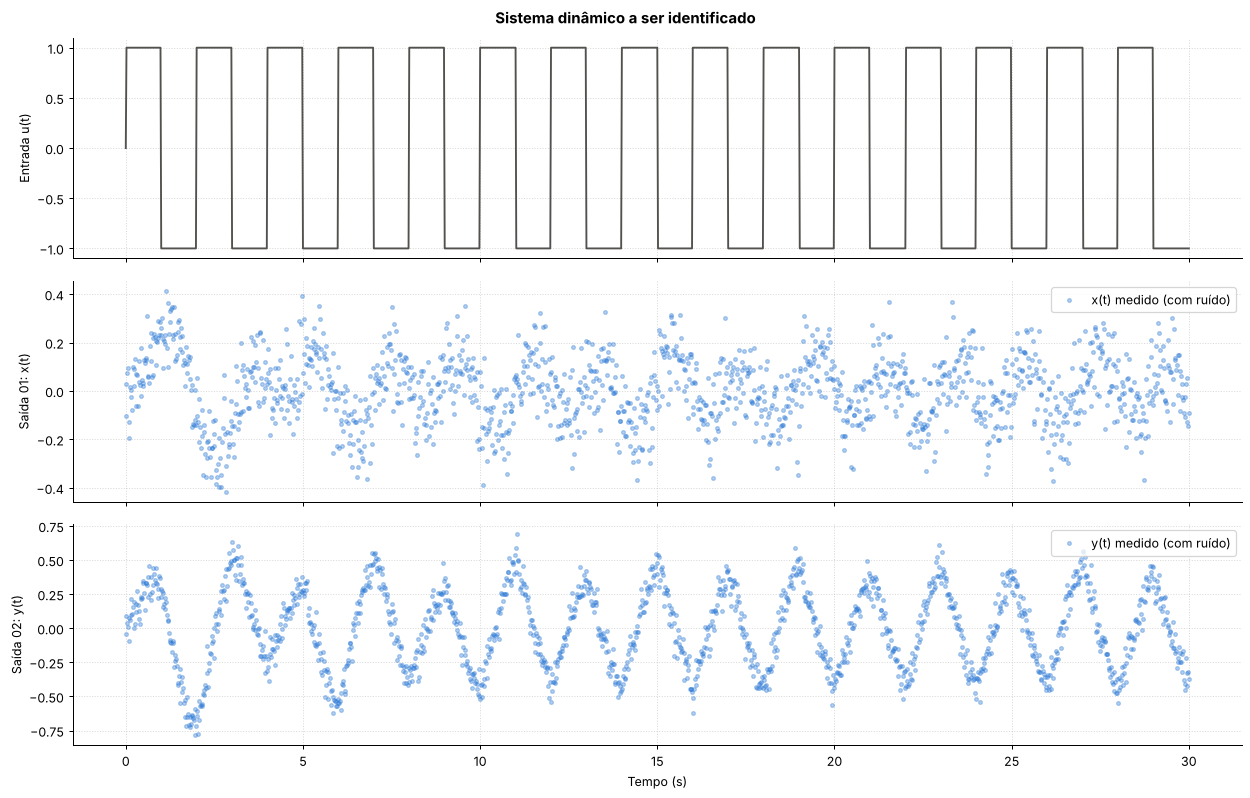

In [3]:
fig, ax = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
fig.suptitle("Sistema dinâmico a ser identificado", fontweight="bold")

ax[0].plot(t, u, color=COR_ENTRADA, lw=1.5)
ax[0].set_ylabel("Entrada u(t)")

ax[1].plot(t, x, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="x(t) medido (com ruído)")
ax[1].set_ylabel("Saída 01: x(t)"); ax[1].legend(loc="upper right")

ax[2].plot(t, y, "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="y(t) medido (com ruído)")
ax[2].set_ylabel("Saída 02: y(t)"); ax[2].set_xlabel("Tempo (s)"); ax[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

**O que observar:**
* A entrada $u$ troca de sinal a cada 1 s (período de 2 s).
* As duas saídas oscilam acompanhando a entrada, mas estão **muito ruidosas** — principalmente $x(t)$, cujo ruído é quase do tamanho do próprio sinal.

---
## 2. Ferramentas usadas por todos os modelos

### 2.1 Erro Médio Quadrático (EMQ)
$$\text{EMQ} = \frac{1}{N}\sum_{i=1}^{N}\big(y_i - \hat y_i\big)^2$$
* $y_i$: valor medido; $\hat y_i$: valor do modelo. Quanto **menor**, melhor.
* $\sqrt{\text{EMQ}}$ é o "erro típico", na mesma unidade do sinal.
* Como os dados têm ruído, nenhum modelo honesto chega a EMQ = 0: o melhor possível é aproximadamente a **variância do ruído**.

### 2.2 Coeficiente de Correlação de Pearson ($r$)
$$r = \frac{\sum_i (y_i - \bar y)(\hat y_i - \bar{\hat y})}{\sqrt{\sum_i (y_i-\bar y)^2}\;\sqrt{\sum_i(\hat y_i - \bar{\hat y})^2}}$$
* Mede o quanto dois sinais "andam juntos" de forma **linear**, de $-1$ a $+1$. $r^2$ é a fração da variação dos dados explicada pelo modelo.

### 2.3 Regressão linear entre dados reais e ajustados
Reta $y_{\text{real}} \approx \alpha + \beta\,\hat y$ pelo MMQ (sistema $2\times 2$, igual ao da aula):
$$\begin{bmatrix} N & \sum \hat y_i \\ \sum \hat y_i & \sum \hat y_i^2 \end{bmatrix}\begin{bmatrix}\alpha\\ \beta\end{bmatrix} = \begin{bmatrix}\sum y_i \\ \sum \hat y_i\, y_i\end{bmatrix}$$
Modelo bom e sem viés: **inclinação $\beta \approx 1$** e **intercepto $\alpha \approx 0$**.

### 2.4 Funções de Base Radial e equação normal
Uma **gaussiana** com centro $\mathbf c_j$ e largura $\sigma$:
$$\phi_j(\mathbf z) = \exp\!\left(-\frac{\lVert \mathbf z - \mathbf c_j\rVert^2}{2\sigma^2}\right)$$
vale 1 quando a entrada $\mathbf z$ está **no centro** e cai para perto de 0 quando está longe. $\lVert \mathbf z - \mathbf c_j\rVert^2$ é a distância ao quadrado: com 1 entrada é $(z - c_j)^2$; com 4 entradas é a soma das 4 diferenças ao quadrado. O modelo RBF soma $M$ gaussianas com pesos:
$$\hat s = w_0 + \sum_{j=1}^{M} w_j\,\phi_j(\mathbf z) \quad\Longrightarrow\quad \hat{\mathbf s} = \Phi\,\mathbf w$$
$\Phi$ é a **matriz de projeto**: uma linha por amostra, uma coluna de 1s (para $w_0$) e uma coluna por gaussiana. O modelo é **não linear na entrada**, mas **linear nos pesos**. Por isso os pesos que minimizam o EMQ saem de um sistema linear, a **equação normal**:
$$\boxed{\Phi^T\Phi\,\mathbf w = \Phi^T\mathbf s}$$
(obtida derivando o EMQ em relação a $\mathbf w$ e igualando a zero). A **mesma** equação serve para o MMQ: só muda o que vai nas colunas da matriz.

In [4]:
def emq(real, ajustado):
    # Erro Médio Quadrático: média dos erros ao quadrado
    erro = real - ajustado
    return np.sum(erro ** 2) / len(erro)

def pearson(a, b):
    # Coeficiente de correlação de Pearson, implementado pela fórmula
    da = a - np.mean(a)              # desvios em relação à média
    db = b - np.mean(b)
    return np.sum(da * db) / np.sqrt(np.sum(da ** 2) * np.sum(db ** 2))

def regressao_linear(xr, yr):
    # Reta yr = alfa + beta * xr pelo MMQ (sistema 2x2 da equação normal)
    A = np.array([[len(xr),     np.sum(xr)],
                  [np.sum(xr),  np.sum(xr * xr)]])
    B = np.array([np.sum(yr), np.sum(xr * yr)])
    alfa, beta = np.linalg.solve(A, B)
    return alfa, beta

def matriz_phi(Z, centros, sigma):
    # Matriz de projeto RBF. Z: (amostras x entradas); centros: (M x entradas).
    # Serve para 1 entrada (tempo) ou 4 entradas (modelo dinâmico).
    Phi = np.ones((len(Z), len(centros) + 1))               # coluna 0 = 1 (bias w0)
    for j in range(len(centros)):
        distancia2 = np.sum((Z - centros[j]) ** 2, axis=1)  # ||z - c_j||²
        Phi[:, j + 1] = np.exp(-distancia2 / (2 * sigma ** 2))
    return Phi

def equacao_normal(A, alvo):
    # Resolve (Aᵀ A) w = Aᵀ alvo  -> pesos que minimizam o erro quadrático
    return np.linalg.solve(A.T @ A, A.T @ alvo)

# Teste rápido: comparando o nosso Pearson com o da NumPy (devem ser iguais)
a_teste, b_teste = np.array([1.0, 2, 3, 4]), np.array([1.1, 1.9, 3.2, 3.9])
print(f"Pearson (nosso) = {pearson(a_teste, b_teste):.6f} | Pearson (np.corrcoef) = {np.corrcoef(a_teste, b_teste)[0, 1]:.6f}")

Pearson (nosso) = 0.993371 | Pearson (np.corrcoef) = 0.993371


---
## 3. Preparação — a RBF no caso mais simples: uma entrada (o tempo)

Antes do modelo dinâmico (4 entradas), vemos a RBF com **uma entrada só**: o tempo $t$. Espalhamos $M$ gaussianas ao longo do eixo do tempo (centros de 0 a 30 s, igualmente espaçados, $\sigma$ = espaçamento entre centros) e ajustamos os pesos para a curva passar "pelo meio" dos pontos. O ruído é rápido e aleatório; a curva suave não consegue segui-lo, então ela funciona como um **filtro**. Essa curva filtrada será usada como **referência** ("sinal sem ruído estimado") nos gráficos seguintes.

**Escolha de $M$ por validação:** separamos 1 de cada 5 amostras (o modelo não as vê), ajustamos com as outras e medimos o EMQ nas escondidas. Poucas gaussianas → curva rígida (*subajuste*); gaussianas demais → curva copia o ruído (*sobreajuste*). Escolhemos o **menor $M$** cujo erro fica até 2% acima do mínimo (**regra da parcimônia**).

x(t): M = 40 gaussianas, centros de 0 a 30 s a cada 0.769 s (σ = 0.769 s) | EMQ = 0.00975 | r = 0.7252
y(t): M = 50 gaussianas, centros de 0 a 30 s a cada 0.612 s (σ = 0.612 s) | EMQ = 0.00535 | r = 0.9675


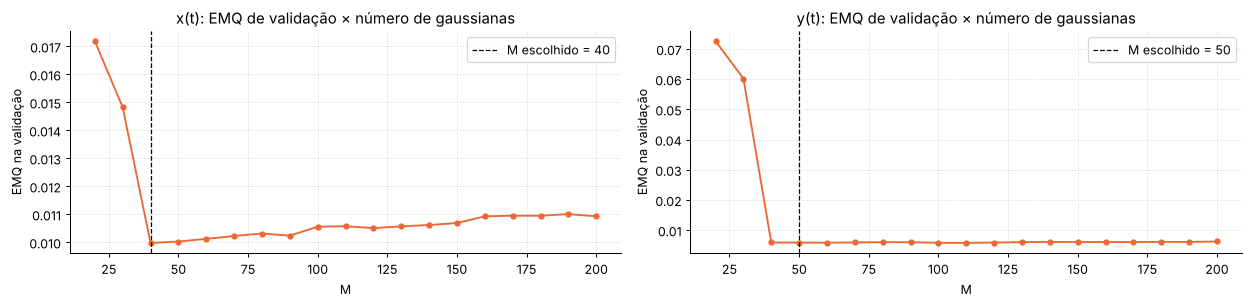

In [5]:
def ajustar_rbf_tempo(tempos, sinal, M):
    centros = np.linspace(0, 30, M)                          # centros no eixo do tempo
    sigma = centros[1] - centros[0]                          # sigma = espaçamento
    Phi = matriz_phi(tempos.reshape(-1, 1), centros.reshape(-1, 1), sigma)
    return equacao_normal(Phi, sinal), centros, sigma

def prever_rbf_tempo(tempos, w, centros, sigma):
    return matriz_phi(tempos.reshape(-1, 1), centros.reshape(-1, 1), sigma) @ w

validacao_t = (np.arange(N) % 5 == 2)        # 1 de cada 5 amostras para validação
treino_t = ~validacao_t
lista_M = np.arange(20, 201, 10)

M_tempo = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for k, (nome, sinal) in enumerate([("x", x), ("y", y)]):
    erros_val = []
    for M in lista_M:
        w, c, s = ajustar_rbf_tempo(t[treino_t], sinal[treino_t], M)
        erros_val.append(emq(sinal[validacao_t], prever_rbf_tempo(t[validacao_t], w, c, s)))
    erros_val = np.array(erros_val)
    limite = 1.02 * erros_val.min()                          # mínimo + 2%
    M_tempo[nome] = int(lista_M[np.where(erros_val <= limite)[0][0]])
    ax[k].plot(lista_M, erros_val, "o-", color=COR_RBF, ms=4)
    ax[k].axvline(M_tempo[nome], color="k", ls="--", lw=1, label=f"M escolhido = {M_tempo[nome]}")
    ax[k].set_title(f"{nome}(t): EMQ de validação × número de gaussianas")
    ax[k].set_xlabel("M"); ax[k].set_ylabel("EMQ na validação"); ax[k].legend()
plt.tight_layout()
plt.show()

w_xt, c_xt, s_xt = ajustar_rbf_tempo(t, x, M_tempo["x"])
w_yt, c_yt, s_yt = ajustar_rbf_tempo(t, y, M_tempo["y"])
x_filtrado = prever_rbf_tempo(t, w_xt, c_xt, s_xt)
y_filtrado = prever_rbf_tempo(t, w_yt, c_yt, s_yt)

for nome, M, c, s, sinal, filt in [("x", M_tempo["x"], c_xt, s_xt, x, x_filtrado),
                                   ("y", M_tempo["y"], c_yt, s_yt, y, y_filtrado)]:
    print(f"{nome}(t): M = {M} gaussianas, centros de {c[0]:.0f} a {c[-1]:.0f} s a cada {s:.3f} s (σ = {s:.3f} s)"
          f" | EMQ = {emq(sinal, filt):.5f} | r = {pearson(sinal, filt):.4f}")

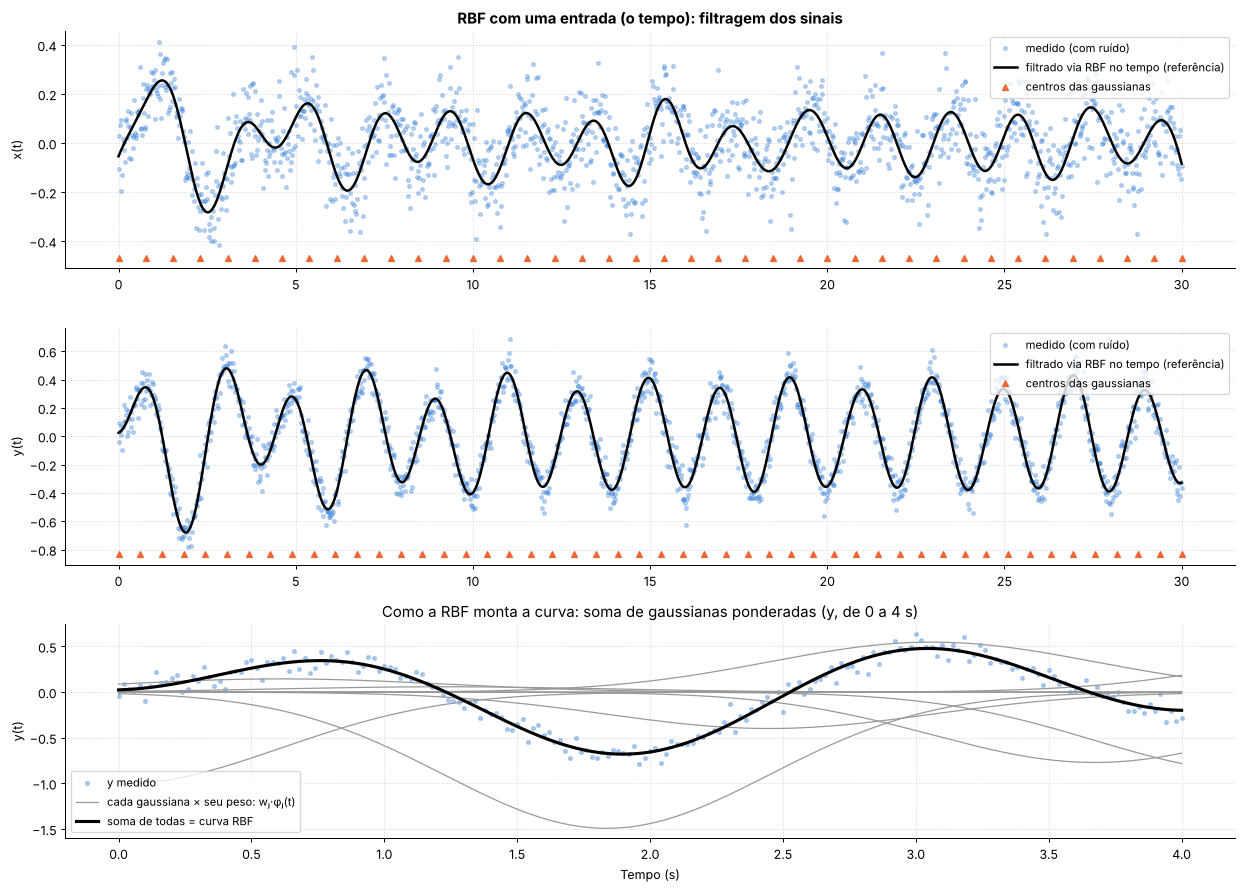

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(14, 10), gridspec_kw={"height_ratios": [1, 1, 0.9]})
for a, medido, filt, c, nome in [(ax[0], x, x_filtrado, c_xt, "x"), (ax[1], y, y_filtrado, c_yt, "y")]:
    a.plot(t, medido, "o", ms=3, alpha=0.3, color=COR_MEDIDO, label="medido (com ruído)")
    a.plot(t, filt, color="k", lw=2, label="filtrado via RBF no tempo (referência)")
    a.plot(c, np.full_like(c, medido.min() - 0.05), "^", color=COR_RBF, ms=5, label="centros das gaussianas")
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right", fontsize=9)
ax[0].set_title("RBF com uma entrada (o tempo): filtragem dos sinais", fontweight="bold")

# Como a curva é montada: soma de sinos ponderados (trecho de 0 a 4 s de y)
trecho = t <= 4
Phi_y = matriz_phi(t.reshape(-1, 1), c_yt.reshape(-1, 1), s_yt)
ax[2].plot(t[trecho], y[trecho], "o", ms=3, alpha=0.35, color=COR_MEDIDO, label="y medido")
for j in range(len(c_yt)):
    if c_yt[j] <= 5:
        ax[2].plot(t[trecho], w_yt[j + 1] * Phi_y[trecho, j + 1], color="0.6", lw=1)
ax[2].plot([], [], color="0.6", lw=1, label="cada gaussiana × seu peso: wⱼ·φⱼ(t)")
ax[2].plot(t[trecho], y_filtrado[trecho], color="k", lw=2.5, label="soma de todas = curva RBF")
ax[2].set_title("Como a RBF monta a curva: soma de gaussianas ponderadas (y, de 0 a 4 s)")
ax[2].set_xlabel("Tempo (s)"); ax[2].set_ylabel("y(t)"); ax[2].legend(loc="lower left", fontsize=9)
plt.tight_layout()
plt.show()

Com uma entrada é fácil **ver** a ideia: os triângulos são os centros (onde cada gaussiana está), e a curva final é a soma dos sinos multiplicados pelos pesos. Na próxima seção a ideia é a mesma, só que cada gaussiana recebe **4 números** em vez de 1.

---
## 4. Ajuste via RBF do modelo dinâmico (Etapas 01, 02 e 03)

### 4.1 O modelo
Agora a RBF implementa exatamente a função do enunciado:
$$\hat s[n] = f\big(s[n-1], s[n-2], u[n], u[n-1]\big) = w_0 + \sum_{j=1}^{M} w_j\,\exp\!\left(-\frac{\lVert \mathbf z[n] - \mathbf c_j\rVert^2}{2\sigma^2}\right), \qquad \mathbf z[n] = \big(s[n-1],\, s[n-2],\, u[n],\, u[n-1]\big)$$
Cada amostra vira um **vetor de 4 números** $\mathbf z[n]$ (as entradas do modelo, chamadas **regressores**) e um **alvo** $s[n]$. Cada centro $\mathbf c_j$ também é um vetor de 4 números, e a gaussiana mede a distância entre os dois nesse espaço de 4 dimensões.

### 4.2 Onde ficam os centros
**Regra:** os centros precisam estar **onde os dados estão** (no mesmo intervalo e na mesma unidade dos regressores). Por isso os centros são **linhas dos próprios dados**. Para cobrir bem o espaço:
* a entrada $(u[n], u[n-1])$ só assume 4 combinações: $(+1,+1)$ e $(-1,-1)$ (entrada parada, ≈ 735 linhas cada) e $(+1,-1)$, $(-1,+1)$ (instantes de troca, ≈ 15 linhas cada);
* para cada combinação, ordenamos as linhas pelo valor de $s[n-1]$ e pegamos linhas **igualmente espaçadas nessa ordem** — assim os centros cobrem desde o menor até o maior valor da saída;
* **10 centros** para cada combinação de entrada parada e **3** para cada combinação de troca (há poucas linhas de troca): $M = 10+10+3+3 = 26$ centros.

Não foi preciso padronizar os dados: $s$ varia entre ≈ −0,8 e 0,7 e $u$ entre −1 e 1, escalas parecidas.

In [7]:
def montar_regressores(s, u):
    # Cada linha: z[n] = [s[n-1], s[n-2], u[n], u[n-1]], para n = 2, ..., N-1
    Z = np.column_stack((s[1:-1],      # s[n-1]
                         s[:-2],       # s[n-2]
                         u[2:],        # u[n]
                         u[1:-1]))     # u[n-1]
    alvo = s[2:]                       # s[n] (o que queremos prever)
    return Z, alvo

def escolher_centros(Z, por_estado=10, por_troca=3):
    centros = []
    for u_atual, u_anterior, quantidade in [(1, 1, por_estado), (-1, -1, por_estado),
                                            (1, -1, por_troca), (-1, 1, por_troca)]:
        linhas = np.where((Z[:, 2] == u_atual) & (Z[:, 3] == u_anterior))[0]
        linhas = linhas[np.argsort(Z[linhas, 0])]                         # ordena por s[n-1]
        escolhidas = linhas[np.linspace(0, len(linhas) - 1, quantidade).astype(int)]
        centros.append(Z[escolhidas])
    return np.vstack(centros)

Z_x, alvo_x = montar_regressores(x, u)
Z_y, alvo_y = montar_regressores(y, u)
t_alvo = t[2:]                          # instante de cada alvo

for u_atual, u_anterior in [(1, 1), (-1, -1), (1, -1), (-1, 1)]:
    qtd = np.sum((Z_x[:, 2] == u_atual) & (Z_x[:, 3] == u_anterior))
    print(f"(u[n], u[n-1]) = ({u_atual:+d}, {u_anterior:+d}): {qtd} linhas")
print(f"Total: {len(Z_x)} linhas (n = 2 ... {N - 1})")

(u[n], u[n-1]) = (+1, +1): 738 linhas
(u[n], u[n-1]) = (-1, -1): 732 linhas
(u[n], u[n-1]) = (+1, -1): 14 linhas
(u[n], u[n-1]) = (-1, +1): 15 linhas
Total: 1499 linhas (n = 2 ... 1500)


### 4.3 Escolha de $\sigma$ (validação)
$\sigma$ diz até que distância cada gaussiana "enxerga". Testamos vários valores e medimos o EMQ em dados não usados no ajuste. Aqui a validação é um **sorteio de 20% das linhas** (com semente fixa, para o resultado ser sempre o mesmo). Não usamos "1 de cada 5" como na Seção 3 porque as trocas de $u$ acontecem a cada 50 amostras (múltiplo de 5): a validação ficaria sem nenhuma linha de troca. Mesmo critério da Seção 3: o **menor $\sigma$** cujo erro fica até 2% acima do mínimo (gaussianas mais "locais" e sistema linear mais bem condicionado).

x: EMQ de validação por σ = [0.01363 0.01308 0.01327 0.01337 0.01342 0.01346] -> σ escolhido = 0.2
y: EMQ de validação por σ = [0.02789 0.00813 0.00664 0.00663 0.00668 0.00668] -> σ escolhido = 0.3


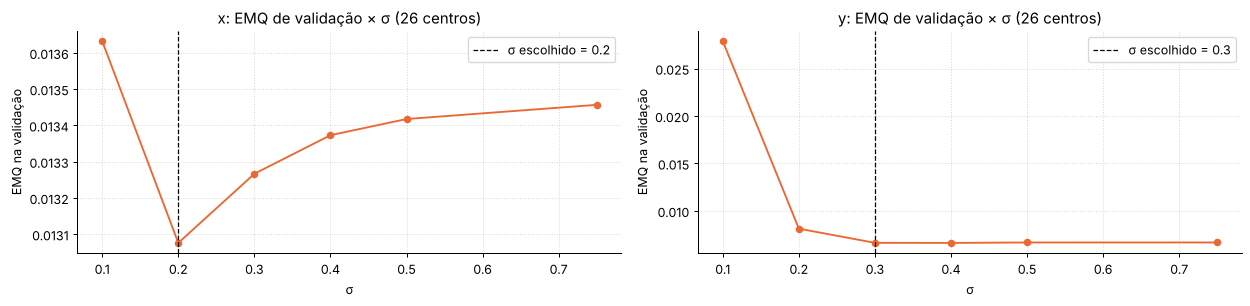

In [8]:
gerador = np.random.default_rng(0)                           # semente fixa
validacao_z = gerador.random(len(alvo_x)) < 0.2              # 20% das linhas para validação
treino_z = ~validacao_z
lista_sigma = [0.1, 0.2, 0.3, 0.4, 0.5, 0.75]

sigma_rbf = {}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
for k, (nome, Z, alvo) in enumerate([("x", Z_x, alvo_x), ("y", Z_y, alvo_y)]):
    centros_tr = escolher_centros(Z[treino_z])
    erros_val = []
    for sigma in lista_sigma:
        w = equacao_normal(matriz_phi(Z[treino_z], centros_tr, sigma), alvo[treino_z])
        erros_val.append(emq(alvo[validacao_z], matriz_phi(Z[validacao_z], centros_tr, sigma) @ w))
    erros_val = np.array(erros_val)
    limite = 1.02 * erros_val.min()
    sigma_rbf[nome] = lista_sigma[np.where(erros_val <= limite)[0][0]]
    ax[k].plot(lista_sigma, erros_val, "o-", color=COR_RBF, ms=5)
    ax[k].axvline(sigma_rbf[nome], color="k", ls="--", lw=1, label=f"σ escolhido = {sigma_rbf[nome]}")
    ax[k].set_title(f"{nome}: EMQ de validação × σ (26 centros)")
    ax[k].set_xlabel("σ"); ax[k].set_ylabel("EMQ na validação"); ax[k].legend()
    print(f"{nome}: EMQ de validação por σ = {np.round(erros_val, 5)} -> σ escolhido = {sigma_rbf[nome]}")
plt.tight_layout()
plt.show()

### 4.4 Ajuste final e parâmetros livres do modelo RBF
Com $\sigma$ escolhido, escolhemos os centros usando **todas** as linhas e calculamos os pesos pela equação normal.

In [9]:
centros_x = escolher_centros(Z_x)
centros_y = escolher_centros(Z_y)
Phi_x = matriz_phi(Z_x, centros_x, sigma_rbf["x"])
Phi_y = matriz_phi(Z_y, centros_y, sigma_rbf["y"])
w_rbf_x = equacao_normal(Phi_x, alvo_x)
w_rbf_y = equacao_normal(Phi_y, alvo_y)

x_rbf = Phi_x @ w_rbf_x                 # previsão RBF para n = 2, ..., N-1
y_rbf = Phi_y @ w_rbf_y

for nome, C, s, w, Phi in [("x", centros_x, sigma_rbf["x"], w_rbf_x, Phi_x),
                           ("y", centros_y, sigma_rbf["y"], w_rbf_y, Phi_y)]:
    print(f"Modelo RBF para {nome}[n]:  M = {len(C)} centros | σ = {s} | {len(w)} pesos (w0 + {len(C)})"
          f" | matriz Φ: {Phi.shape[0]} x {Phi.shape[1]}")
    print(f"  w0 = {w[0]:.4f}")
    print("  primeiros centros  [s[n-1], s[n-2], u[n], u[n-1]]  e seus pesos:")
    for j in [0, 1, 2, 10, 20, 23]:
        print(f"    c{j + 1:<2} = {np.round(C[j], 3)}   w{j + 1} = {w[j + 1]:.4f}")

Modelo RBF para x[n]:  M = 26 centros | σ = 0.2 | 27 pesos (w0 + 26) | matriz Φ: 1499 x 27
  w0 = -0.0190
  primeiros centros  [s[n-1], s[n-2], u[n], u[n-1]]  e seus pesos:
    c1  = [-0.416 -0.309  1.     1.   ]   w1 = -0.0965
    c2  = [-0.23  -0.154  1.     1.   ]   w2 = -1.7898
    c3  = [-0.17  -0.141  1.     1.   ]   w3 = 3.7916
    c11 = [-0.273 -0.22  -1.    -1.   ]   w11 = -0.2539
    c21 = [-0.199 -0.239  1.    -1.   ]   w21 = 0.0754
    c24 = [-0.149 -0.018 -1.     1.   ]   w24 = 0.1027
Modelo RBF para y[n]:  M = 26 centros | σ = 0.3 | 27 pesos (w0 + 26) | matriz Φ: 1499 x 27
  w0 = -0.0290
  primeiros centros  [s[n-1], s[n-2], u[n], u[n-1]]  e seus pesos:
    c1  = [-0.774 -0.609  1.     1.   ]   w1 = -0.6045
    c2  = [-0.355 -0.433  1.     1.   ]   w2 = 0.1629
    c3  = [-0.224 -0.281  1.     1.   ]   w3 = -0.6498
    c11 = [-0.782 -0.59  -1.    -1.   ]   w11 = -0.6658
    c21 = [-0.718 -0.782  1.    -1.   ]   w21 = -0.5481
    c24 = [ 0.231  0.37  -1.     1.   ]   w24 = 

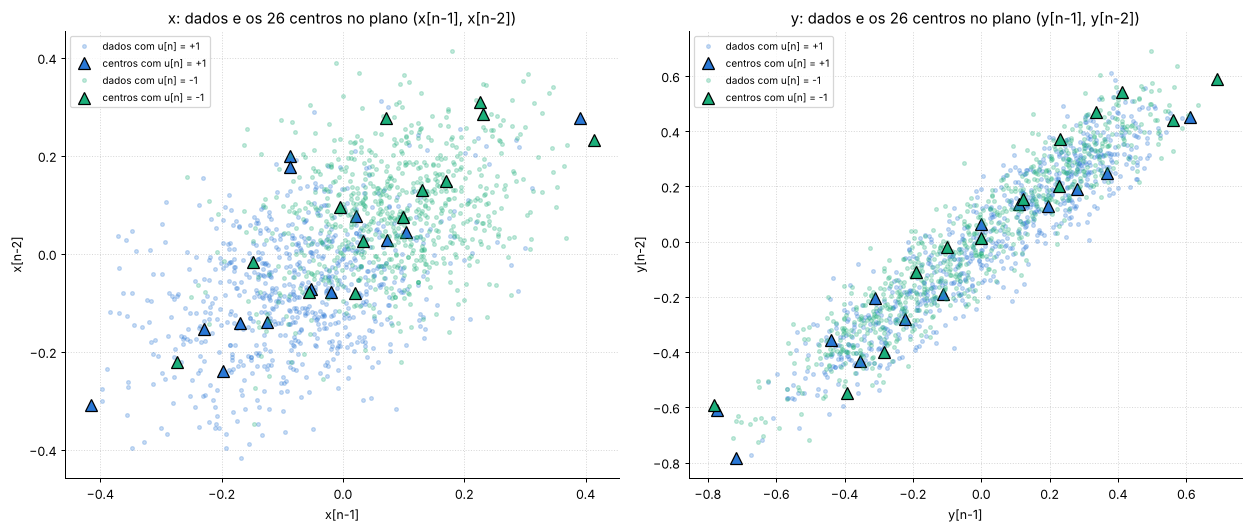

In [10]:
# Onde estão os centros: plano (s[n-1], s[n-2]), cor = valor de u[n]
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, Z, C, nome in [(ax[0], Z_x, centros_x, "x"), (ax[1], Z_y, centros_y, "y")]:
    for valor_u, cor in [(1, COR_MEDIDO), (-1, "#1baf7a")]:
        sel = Z[:, 2] == valor_u
        a.plot(Z[sel, 0], Z[sel, 1], "o", ms=3, alpha=0.25, color=cor, label=f"dados com u[n] = {valor_u:+d}")
        selc = C[:, 2] == valor_u
        a.plot(C[selc, 0], C[selc, 1], "^", ms=10, color=cor, markeredgecolor="k", label=f"centros com u[n] = {valor_u:+d}")
    a.set_xlabel(f"{nome}[n-1]"); a.set_ylabel(f"{nome}[n-2]")
    a.set_title(f"{nome}: dados e os {len(C)} centros no plano ({nome}[n-1], {nome}[n-2])")
    a.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

O gráfico mostra 2 das 4 coordenadas de cada centro (as outras duas são os valores de $u$, indicados pela cor). Os centros (triângulos) estão **sobre a nuvem de dados**, cobrindo toda a faixa de valores. Os pontos ficam perto da diagonal porque $s[n-1]$ e $s[n-2]$ são amostras vizinhas (0,02 s de diferença), logo quase iguais.

### 4.5 Etapas 01 e 02 — Ajuste obtido via RBF e EMQ
A previsão de cada instante usa os **valores medidos** anteriores (**predição um passo à frente**). A curva preta tracejada é o sinal filtrado da Seção 3, só como referência visual.

EMQ x (RBF) = 0.01195   ->  erro típico √EMQ = 0.1093
EMQ y (RBF) = 0.00757   ->  erro típico √EMQ = 0.0870


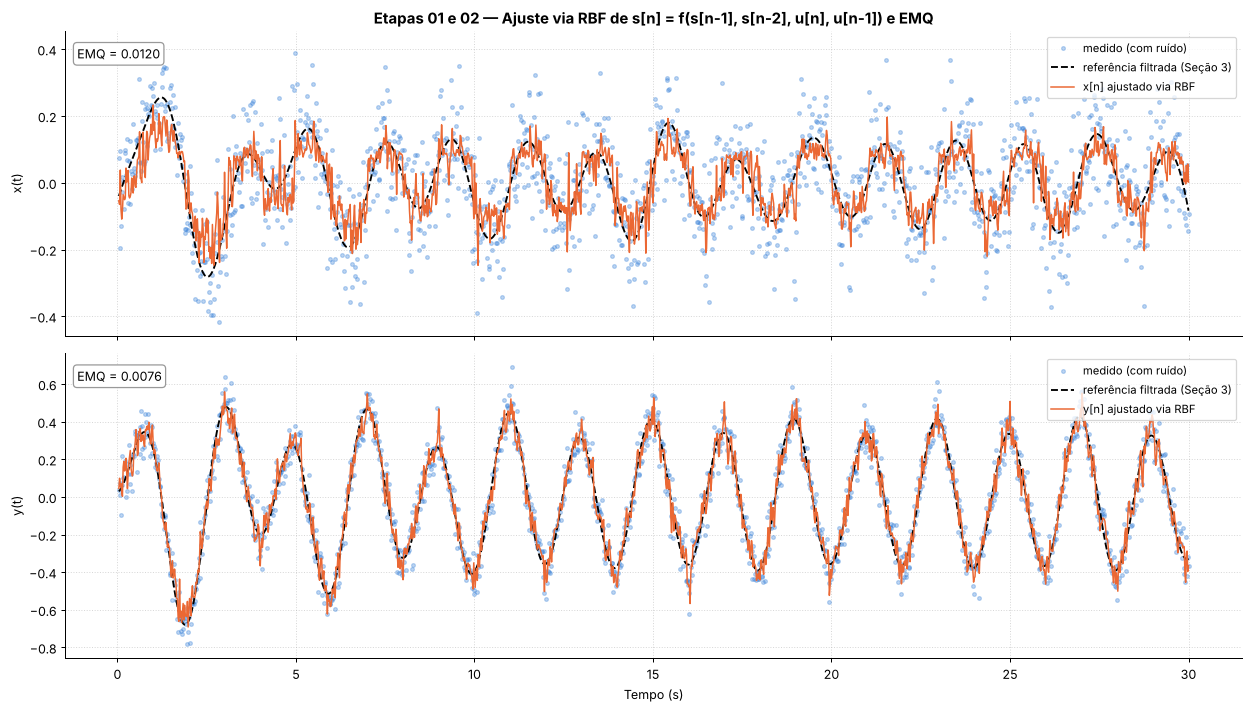

In [11]:
EMQ_x_rbf = emq(alvo_x, x_rbf)
EMQ_y_rbf = emq(alvo_y, y_rbf)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, filt, nome, e in [(ax[0], alvo_x, x_rbf, x_filtrado[2:], "x", EMQ_x_rbf),
                                         (ax[1], alvo_y, y_rbf, y_filtrado[2:], "y", EMQ_y_rbf)]:
    a.plot(t_alvo, medido, "o", ms=3, alpha=0.3, color=COR_MEDIDO, label="medido (com ruído)")
    a.plot(t_alvo, filt, "k--", lw=1.5, label="referência filtrada (Seção 3)")
    a.plot(t_alvo, ajuste, color=COR_RBF, lw=1.2, label=f"{nome}[n] ajustado via RBF")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Etapas 01 e 02 — Ajuste via RBF de s[n] = f(s[n-1], s[n-2], u[n], u[n-1]) e EMQ", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

print(f"EMQ x (RBF) = {EMQ_x_rbf:.5f}   ->  erro típico √EMQ = {np.sqrt(EMQ_x_rbf):.4f}")
print(f"EMQ y (RBF) = {EMQ_y_rbf:.5f}   ->  erro típico √EMQ = {np.sqrt(EMQ_y_rbf):.4f}")

A curva da RBF é **serrilhada**: como ela recebe os valores medidos (com ruído) de $s[n-1]$ e $s[n-2]$, parte do ruído "entra" na previsão. Mesmo assim, ela acompanha a forma da referência filtrada.

### 4.6 Etapa 03 — Regressão linear entre dados reais e ajustados + Correlação de Pearson
Cada ponto é um instante: no eixo horizontal o valor **ajustado**, no vertical o **medido**. As faixas mostram $\pm\sqrt{\text{EMQ}}$ em torno da reta de regressão.

x: reta real = -0.0000 + 1.0000·ajustado | Pearson r = 0.6475 | r² = 0.4193
y: reta real = 0.0000 + 1.0000·ajustado | Pearson r = 0.9538 | r² = 0.9097


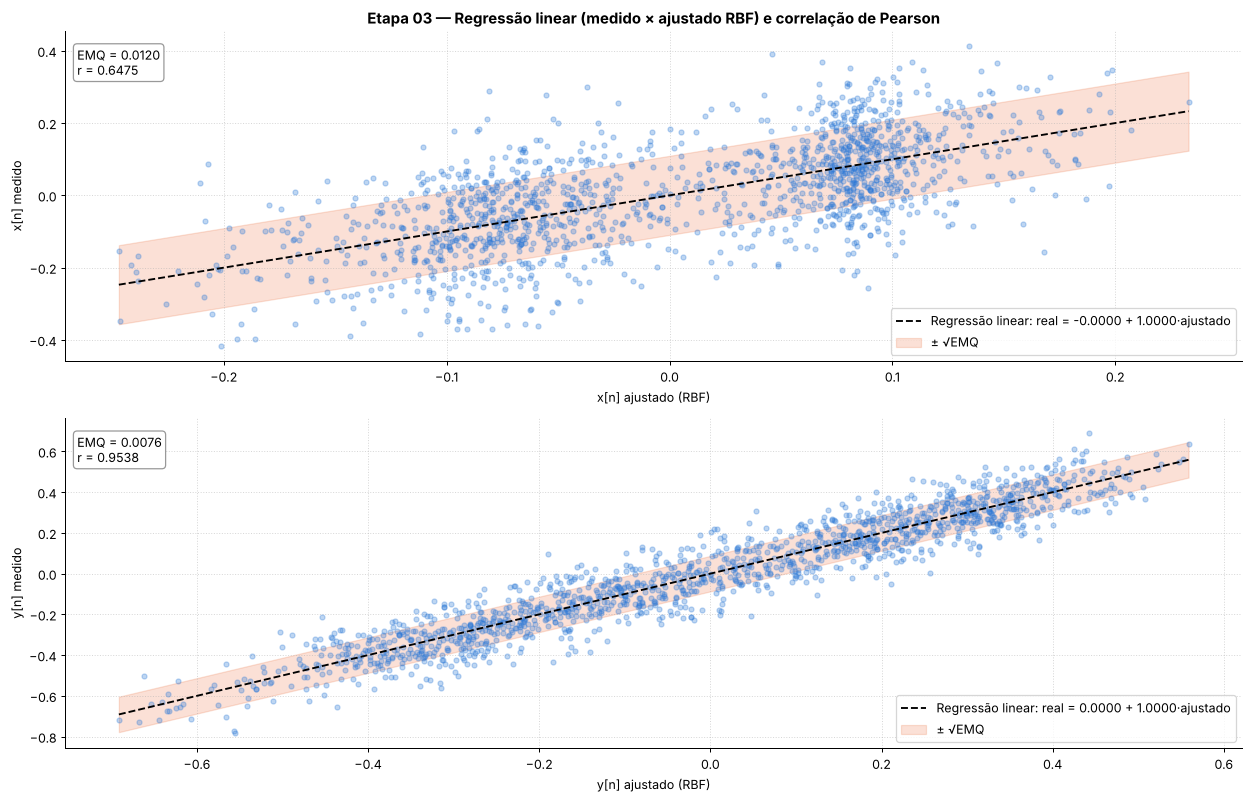

In [12]:
def grafico_regressao(ax, ajustado, real, nome, cor, rotulo_modelo):
    alfa, beta = regressao_linear(ajustado, real)
    r = pearson(real, ajustado)
    e = emq(real, ajustado)
    xs = np.linspace(ajustado.min(), ajustado.max(), 100)
    reta = alfa + beta * xs
    ax.plot(ajustado, real, "o", ms=4, alpha=0.3, color=COR_MEDIDO)
    ax.plot(xs, reta, "k--", lw=1.5, label=f"Regressão linear: real = {alfa:.4f} + {beta:.4f}·ajustado")
    ax.fill_between(xs, reta - np.sqrt(e), reta + np.sqrt(e), color=cor, alpha=0.2, label="± √EMQ")
    ax.text(0.01, 0.95, f"EMQ = {e:.4f}\nr = {r:.4f}", transform=ax.transAxes, va="top",
            bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    ax.set_xlabel(f"{nome}[n] ajustado ({rotulo_modelo})"); ax.set_ylabel(f"{nome}[n] medido")
    ax.legend(loc="lower right")
    return alfa, beta, r

fig, ax = plt.subplots(2, 1, figsize=(14, 9))
alfa_x_rbf, beta_x_rbf, r_x_rbf = grafico_regressao(ax[0], x_rbf, alvo_x, "x", COR_RBF, "RBF")
alfa_y_rbf, beta_y_rbf, r_y_rbf = grafico_regressao(ax[1], y_rbf, alvo_y, "y", COR_RBF, "RBF")
ax[0].set_title("Etapa 03 — Regressão linear (medido × ajustado RBF) e correlação de Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x: reta real = {alfa_x_rbf:.4f} + {beta_x_rbf:.4f}·ajustado | Pearson r = {r_x_rbf:.4f} | r² = {r_x_rbf**2:.4f}")
print(f"y: reta real = {alfa_y_rbf:.4f} + {beta_y_rbf:.4f}·ajustado | Pearson r = {r_y_rbf:.4f} | r² = {r_y_rbf**2:.4f}")

**Leitura dos resultados:**
* A inclinação deu **exatamente 1** e o intercepto **exatamente 0**. É uma propriedade do MMQ com termo constante ($w_0$): quando os pesos minimizam o EMQ, o erro fica ortogonal à coluna de 1s e à própria curva ajustada, então a melhor reta entre medido e ajustado é $y = 0 + 1\cdot\hat y$. Ou seja, o ajuste **não tem viés**.
* O $r$ de $y$ é bem maior que o de $x$. Não é porque o modelo "errou mais" em $x$: em $x$ o **ruído é quase do tamanho do sinal** (relação sinal/ruído baixa), então até a curva verdadeira teria correlação moderada com os pontos medidos.

---
## 5. Repetição do processo com o MMQ — Etapa 04

### 5.1 O modelo linear
Mesma função do enunciado, agora com $f$ **linear**:
$$\boxed{s[n] = a_1\,s[n-1] + a_2\,s[n-2] + b_0\,u[n] + b_1\,u[n-1]}$$
É uma **equação de diferenças** de 2ª ordem (modelo ARX), a versão discreta de uma equação diferencial de 2ª ordem (como massa-mola-amortecedor ou circuito RLC). Os **parâmetros livres** são $a_1, a_2$ ("memória"/inércia do sistema) e $b_0, b_1$ (efeito da entrada).

### 5.2 Forma matricial e solução por MMQ
A matriz agora é a própria matriz de regressores $Z$ (1499 linhas × 4 colunas): cada linha $[s[n-1], s[n-2], u[n], u[n-1]]$. São 1499 equações para 4 incógnitas (sistema sobredeterminado), e o MMQ leva à mesma equação normal:
$$\boxed{Z^TZ\,\theta = Z^T\mathbf s}, \qquad \theta = (a_1, a_2, b_0, b_1)$$
Diferença em relação à RBF: na RBF os 4 regressores passam pelas gaussianas antes de entrar na matriz; no MMQ eles entram **diretamente**.

Parâmetros livres do modelo s[n] = a1·s[n-1] + a2·s[n-2] + b0·u[n] + b1·u[n-1]

saída           a1        a2        b0        b1
x           0.2984    0.2118   -0.0216   -0.0150
y           0.4876    0.4649   -0.0159    0.0426

EMQ x (MMQ) = 0.01226
EMQ y (MMQ) = 0.00753


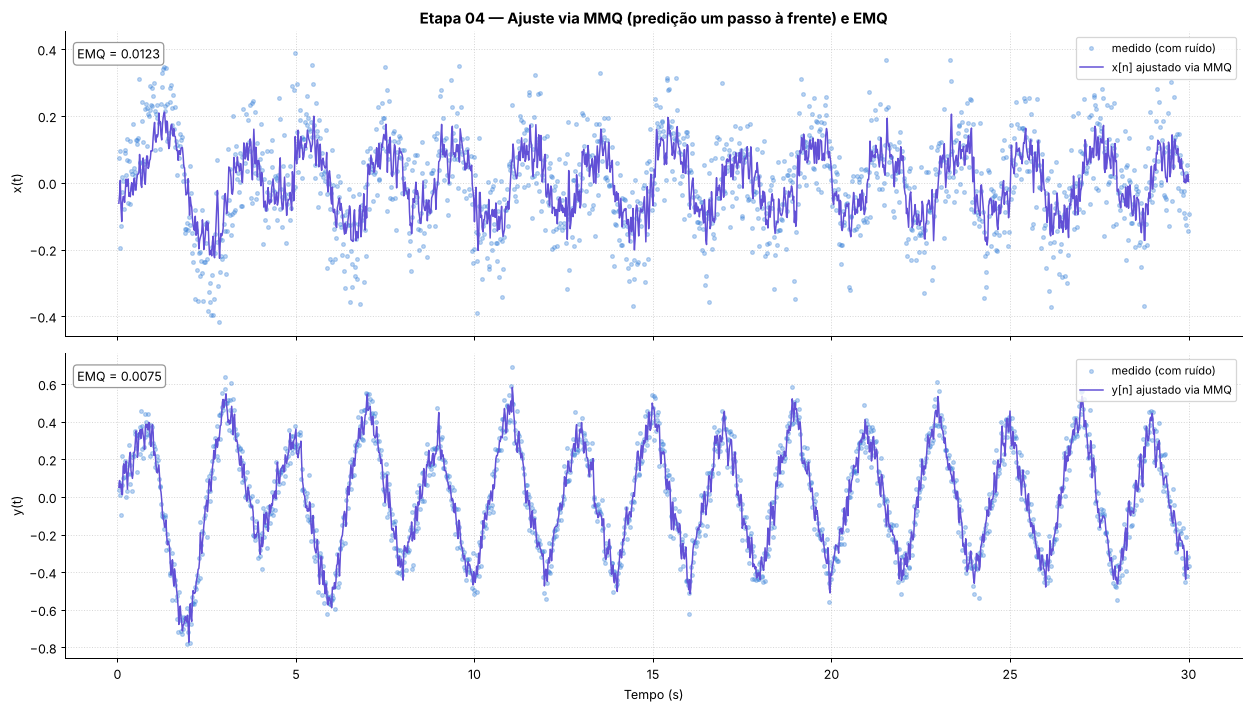

In [13]:
theta_x = equacao_normal(Z_x, alvo_x)
theta_y = equacao_normal(Z_y, alvo_y)

print("Parâmetros livres do modelo s[n] = a1·s[n-1] + a2·s[n-2] + b0·u[n] + b1·u[n-1]\n")
print(f"{'saída':<8}{'a1':>10}{'a2':>10}{'b0':>10}{'b1':>10}")
for nome, th in [("x", theta_x), ("y", theta_y)]:
    print(f"{nome:<8}{th[0]:>10.4f}{th[1]:>10.4f}{th[2]:>10.4f}{th[3]:>10.4f}")

x_mmq = Z_x @ theta_x                   # previsão um passo à frente
y_mmq = Z_y @ theta_y
EMQ_x_mmq = emq(alvo_x, x_mmq)
EMQ_y_mmq = emq(alvo_y, y_mmq)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, ajuste, nome, e in [(ax[0], alvo_x, x_mmq, "x", EMQ_x_mmq), (ax[1], alvo_y, y_mmq, "y", EMQ_y_mmq)]:
    a.plot(t_alvo, medido, "o", ms=3, alpha=0.3, color=COR_MEDIDO, label="medido (com ruído)")
    a.plot(t_alvo, ajuste, color=COR_MMQ, lw=1.2, label=f"{nome}[n] ajustado via MMQ")
    a.text(0.01, 0.95, f"EMQ = {e:.4f}", transform=a.transAxes, va="top",
           bbox=dict(boxstyle="round", fc="white", ec="0.6"))
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Etapa 04 — Ajuste via MMQ (predição um passo à frente) e EMQ", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

print(f"\nEMQ x (MMQ) = {EMQ_x_mmq:.5f}")
print(f"EMQ y (MMQ) = {EMQ_y_mmq:.5f}")

### 5.3 Regressão linear e correlação de Pearson do ajuste MMQ

x: reta real = 0.0022 + 0.9995·ajustado | Pearson r = 0.6361 | r² = 0.4046
y: reta real = -0.0007 + 1.0000·ajustado | Pearson r = 0.9541 | r² = 0.9102


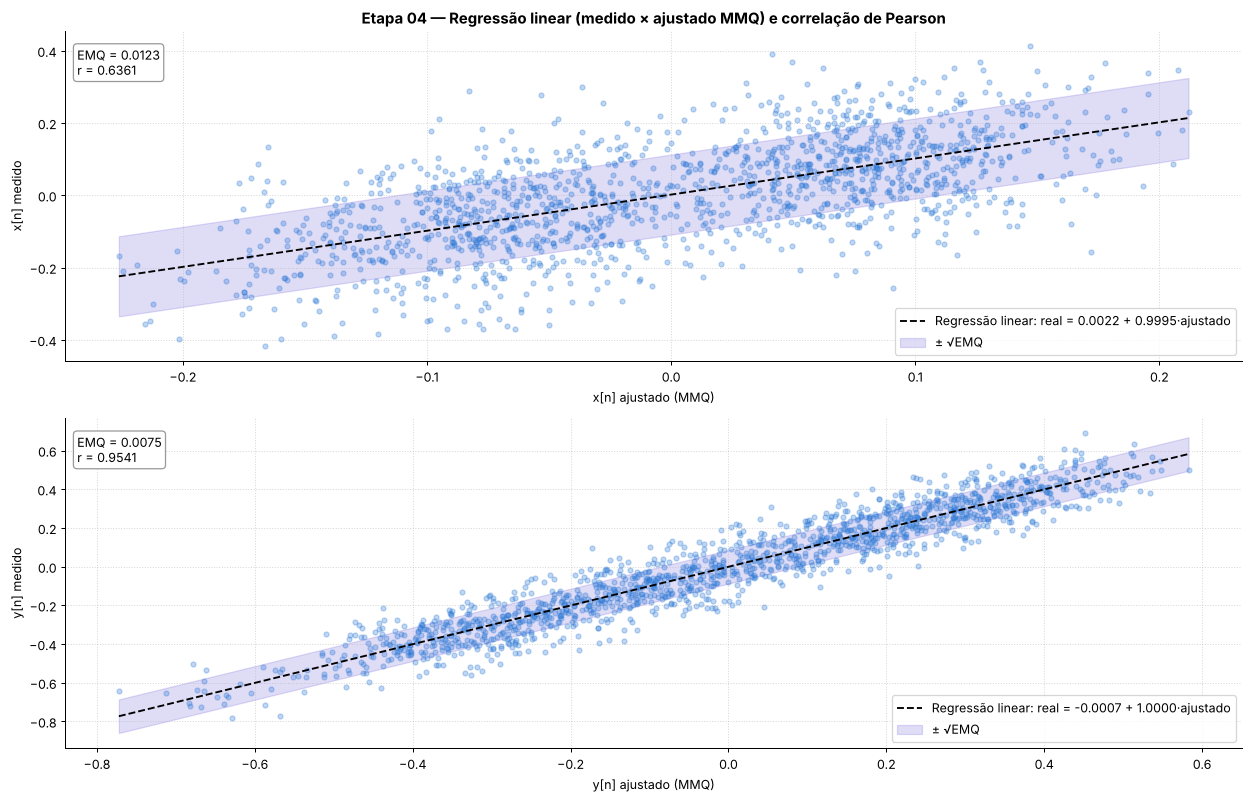

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(14, 9))
alfa_x_mmq, beta_x_mmq, r_x_mmq = grafico_regressao(ax[0], x_mmq, alvo_x, "x", COR_MMQ, "MMQ")
alfa_y_mmq, beta_y_mmq, r_y_mmq = grafico_regressao(ax[1], y_mmq, alvo_y, "y", COR_MMQ, "MMQ")
ax[0].set_title("Etapa 04 — Regressão linear (medido × ajustado MMQ) e correlação de Pearson", fontweight="bold")
plt.tight_layout()
plt.show()

print(f"x: reta real = {alfa_x_mmq:.4f} + {beta_x_mmq:.4f}·ajustado | Pearson r = {r_x_mmq:.4f} | r² = {r_x_mmq**2:.4f}")
print(f"y: reta real = {alfa_y_mmq:.4f} + {beta_y_mmq:.4f}·ajustado | Pearson r = {r_y_mmq:.4f} | r² = {r_y_mmq**2:.4f}")

Aqui a inclinação é só **quase** 1 e o intercepto **quase** 0: o modelo MMQ do enunciado não tem termo constante, então a propriedade da Seção 4.6 não vale exatamente.

---
## 6. Complemento — os modelos conseguem *simular* o sistema sozinhos?
A predição um passo à frente sempre recebe o valor **medido** anterior. O teste mais exigente é a **simulação livre**: o modelo recebe **apenas a entrada $u$** (e as duas primeiras amostras) e usa as **próprias previsões** como passado:
$$\hat s[n] = f\big(\hat s[n-1],\, \hat s[n-2],\, u[n],\, u[n-1]\big)$$
Se o modelo capturou a dinâmica verdadeira, essa simulação reproduz o sinal.

x: RBF livre  EMQ = 0.01488, r = 0.5279  |  MMQ livre  EMQ = 0.01497, r = 0.5238
y: RBF livre  EMQ = 0.01410, r = 0.9204  |  MMQ livre  EMQ = 0.01970, r = 0.8777


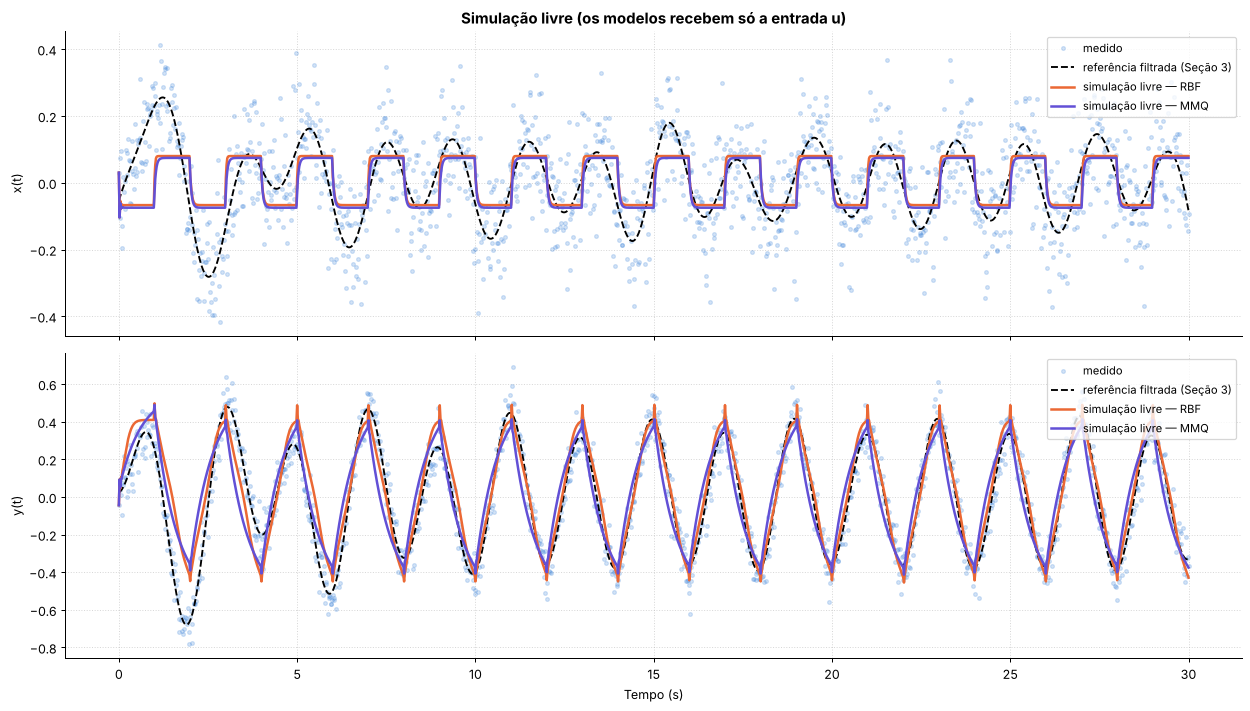

In [15]:
def simular_livre(modelo, u, s_inicial):
    # modelo: função que recebe z = [s[n-1], s[n-2], u[n], u[n-1]] e devolve s[n]
    s_sim = np.zeros(len(u))
    s_sim[0], s_sim[1] = s_inicial[0], s_inicial[1]          # condições iniciais = 2 primeiras medidas
    for n in range(2, len(u)):
        z = np.array([s_sim[n - 1], s_sim[n - 2], u[n], u[n - 1]])
        s_sim[n] = modelo(z)
    return s_sim

modelo_rbf_x = lambda z: (matriz_phi(z.reshape(1, -1), centros_x, sigma_rbf["x"]) @ w_rbf_x)[0]
modelo_rbf_y = lambda z: (matriz_phi(z.reshape(1, -1), centros_y, sigma_rbf["y"]) @ w_rbf_y)[0]
modelo_mmq_x = lambda z: z @ theta_x
modelo_mmq_y = lambda z: z @ theta_y

x_sim_rbf = simular_livre(modelo_rbf_x, u, x)
y_sim_rbf = simular_livre(modelo_rbf_y, u, y)
x_sim_mmq = simular_livre(modelo_mmq_x, u, x)
y_sim_mmq = simular_livre(modelo_mmq_y, u, y)

fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
for a, medido, filt, s_rbf, s_mmq, nome in [(ax[0], x, x_filtrado, x_sim_rbf, x_sim_mmq, "x"),
                                            (ax[1], y, y_filtrado, y_sim_rbf, y_sim_mmq, "y")]:
    a.plot(t, medido, "o", ms=3, alpha=0.2, color=COR_MEDIDO, label="medido")
    a.plot(t, filt, "k--", lw=1.5, label="referência filtrada (Seção 3)")
    a.plot(t, s_rbf, color=COR_RBF, lw=2, label="simulação livre — RBF")
    a.plot(t, s_mmq, color=COR_MMQ, lw=2, label="simulação livre — MMQ")
    a.set_ylabel(f"{nome}(t)"); a.legend(loc="upper right", fontsize=9)
ax[0].set_title("Simulação livre (os modelos recebem só a entrada u)", fontweight="bold")
ax[1].set_xlabel("Tempo (s)")
plt.tight_layout()
plt.show()

for nome, medido, s_rbf, s_mmq in [("x", x, x_sim_rbf, x_sim_mmq), ("y", y, y_sim_rbf, y_sim_mmq)]:
    print(f"{nome}: RBF livre  EMQ = {emq(medido[2:], s_rbf[2:]):.5f}, r = {pearson(medido[2:], s_rbf[2:]):.4f}"
          f"  |  MMQ livre  EMQ = {emq(medido[2:], s_mmq[2:]):.5f}, r = {pearson(medido[2:], s_mmq[2:]):.4f}")

---
## 7. Comparação final

In [16]:
print(f"{'Modelo':<38}{'Saída':<7}{'EMQ':>10}{'√EMQ':>9}{'Pearson r':>11}{'r²':>8}")
print("-" * 83)
linhas_tabela = [
    ("RBF dinâmica - um passo à frente",   "x", EMQ_x_rbf, r_x_rbf),
    ("RBF dinâmica - um passo à frente",   "y", EMQ_y_rbf, r_y_rbf),
    ("MMQ - um passo à frente",            "x", EMQ_x_mmq, r_x_mmq),
    ("MMQ - um passo à frente",            "y", EMQ_y_mmq, r_y_mmq),
    ("RBF dinâmica - simulação livre",     "x", emq(x[2:], x_sim_rbf[2:]), pearson(x[2:], x_sim_rbf[2:])),
    ("RBF dinâmica - simulação livre",     "y", emq(y[2:], y_sim_rbf[2:]), pearson(y[2:], y_sim_rbf[2:])),
    ("MMQ - simulação livre",              "x", emq(x[2:], x_sim_mmq[2:]), pearson(x[2:], x_sim_mmq[2:])),
    ("MMQ - simulação livre",              "y", emq(y[2:], y_sim_mmq[2:]), pearson(y[2:], y_sim_mmq[2:])),
    ("Referência: RBF no tempo (filtro)",  "x", emq(x, x_filtrado), pearson(x, x_filtrado)),
    ("Referência: RBF no tempo (filtro)",  "y", emq(y, y_filtrado), pearson(y, y_filtrado)),
]
for modelo, saida, e, r in linhas_tabela:
    print(f"{modelo:<38}{saida:<7}{e:>10.5f}{np.sqrt(e):>9.4f}{r:>11.4f}{r**2:>8.4f}")

print(f"\nNúmero de parâmetros: RBF dinâmica = {len(w_rbf_x)} pesos por saída (+ σ e 26 centros) | MMQ = 4 por saída")

Modelo                                Saída         EMQ     √EMQ  Pearson r      r²
-----------------------------------------------------------------------------------
RBF dinâmica - um passo à frente      x         0.01195   0.1093     0.6475  0.4193
RBF dinâmica - um passo à frente      y         0.00757   0.0870     0.9538  0.9097
MMQ - um passo à frente               x         0.01226   0.1107     0.6361  0.4046
MMQ - um passo à frente               y         0.00753   0.0868     0.9541  0.9102
RBF dinâmica - simulação livre        x         0.01488   0.1220     0.5279  0.2787
RBF dinâmica - simulação livre        y         0.01410   0.1187     0.9204  0.8471
MMQ - simulação livre                 x         0.01497   0.1224     0.5238  0.2744
MMQ - simulação livre                 y         0.01970   0.1404     0.8777  0.7703
Referência: RBF no tempo (filtro)     x         0.00975   0.0987     0.7252  0.5259
Referência: RBF no tempo (filtro)     y         0.00535   0.0731     0.9675 

---
## 8. Conclusões

**1. Os dois métodos implementam o modelo do enunciado, $s[n] = f(s[n-1], s[n-2], u[n], u[n-1])$.** Na RBF, $f$ é uma soma de 26 gaussianas em 4 dimensões; no MMQ, $f$ é uma combinação linear com 4 parâmetros. Em ambos os casos os pesos saem da mesma equação normal.

**2. Na predição um passo à frente, RBF e MMQ praticamente empatam.**

| Saída | RBF: EMQ | RBF: $r$ | MMQ: EMQ | MMQ: $r$ |
|---|---|---|---|---|
| $x$ | 0,0120 | 0,648 | 0,0123 | 0,636 |
| $y$ | 0,0076 | 0,954 | 0,0075 | 0,954 |

A flexibilidade extra das gaussianas quase não ajuda. Isso indica que, com esse nível de ruído, a relação entre o passado e o próximo valor é **essencialmente linear**: o MMQ, com só 4 parâmetros, já captura quase tudo que dá para prever. Pelo princípio da parcimônia, para predição um passo à frente o modelo linear é suficiente.

**3. Na simulação livre (o teste mais exigente), a RBF foi melhor em $y$.** Recebendo só a entrada $u$, a RBF reproduziu $y$ com EMQ = 0,0141 e $r = 0{,}920$, contra EMQ = 0,0197 e $r = 0{,}878$ do MMQ (erro 28% menor). As gaussianas reproduzem melhor a forma dos picos. Em $x$ os dois modelos falham da mesma forma ($r \approx 0{,}53$): reproduzem só uma onda quadrada.

**4. Por que a simulação de $x$ falha: ruído nos regressores.** Como $s[n-1]$ e $s[n-2]$ também são medidas com ruído, o ajuste por mínimos quadrados "desconfia" do passado e subestima a memória do sistema. Os parâmetros do MMQ mostram isso: para um sinal que oscila suavemente amostrado a cada 0,02 s esperaríamos $a_1 \approx 2$ e $a_2 \approx -1$, mas obtivemos:

| Saída | $a_1$ | $a_2$ | $b_0$ | $b_1$ |
|---|---|---|---|---|
| $x$ | 0,2984 | 0,2118 | −0,0216 | −0,0150 |
| $y$ | 0,4876 | 0,4649 | −0,0159 | 0,0426 |

O efeito é muito mais forte em $x$, cujo ruído é quase do tamanho do sinal.

**5. A saída $y$ é sempre melhor modelada que $x$.** É a **relação sinal/ruído**: em $x$ o erro típico ($\sqrt{\text{EMQ}} \approx 0{,}11$) é do tamanho da amplitude do sinal ($\approx 0{,}1$ a $0{,}25$); em $y$ a amplitude ($\approx 0{,}4$ a $0{,}7$) é bem maior que o erro ($\approx 0{,}09$).

**6. A RBF no tempo (Seção 3) mostra o limite do ruído.** Ela teve o menor EMQ (0,0098 em $x$ e 0,0054 em $y$), que é aproximadamente a variância do ruído: o melhor erro possível contra dados medidos. Mas ela **não é um modelo dinâmico**: descreve só estes 30 s e não sabe responder a uma entrada diferente. Os modelos dinâmicos ficam um pouco acima desse limite porque usam valores passados ruidosos como entrada.

**7. Os ajustes não têm viés.** Na regressão medido × ajustado, a RBF deu inclinação 1 e intercepto 0 exatos (propriedade do MMQ com termo constante); o MMQ deu 0,9995 e 0,0022 em $x$ e 1,0000 e −0,0007 em $y$.

**8. EMQ e Pearson se complementam.** O EMQ mede o **tamanho** do erro; o $r$ mede se a **forma** do sinal foi capturada. Usar os dois, junto com a reta de regressão ($\beta \approx 1$, $\alpha \approx 0$), evita conclusões erradas.

**Possíveis melhorias:** identificar os modelos a partir do sinal já filtrado, aumentar a ordem do modelo (mais atrasos), ou usar métodos próprios para ruído nos regressores (por exemplo, variáveis instrumentais).